> **AI-use disclosure.** This notebook was developed with the help of **Claude Code (Anthropic)** in VS Code.
> * **AI-generated / AI-assisted:** code structure, the data-processing and model code (in `src/` and the cells below),
>   plotting code, and first drafts of the explanatory markdown.
> * **Done by the student (B. G. M. Prabuddhi):** choice of the problem and the Sri Lankan dataset, making and approving
>   the data and modelling decisions, reviewing the code, running the notebook, checking the outputs, and interpreting the results.
>
> Full details: [`AI_DISCLOSURE.md`](../AI_DISCLOSURE.md).

# 07 · Final comparison: which ensemble approach works best for Sri Lankan dengue forecasting, and why?

**Goal.** Bring every model together on the **same 2023–2026 test weeks** (all districts, one-week-ahead, original
case scale), pick the winners **using validation MAE only**, and explain the behaviour we observe with ensemble theory
and the properties of this data.

Contents: (1) the comparison table, (2) winners, (3) charts, (4) RF vs gradient-boosting head-to-head, (5) normal vs
outbreak weeks and distribution shift, (6) feature importance and SHAP, (7) *why the models behaved this way*,
(8) research notes (RF vs XGBoost/LightGBM/CatBoost; tabular vs image/text), (9) limitations,
(10) `models/summary.json` for the dashboard.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # make `src` importable from the notebook
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, viz
viz.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30)

from src import models as M, evaluate as E, features as F
cfg, splits, feats = M.load_data()
tr, va, te = splits["train"], splits["val"], splits["test"]
res = E.results_table()
reg = M.load_registry()
naive = res.set_index("model").loc[E.NAIVE_NAME]
print(f"test rows: {len(te):,} district-weeks ({te.target_date.min().date()} to {te.target_date.max().date()}), "
      f"of which {E.outbreak_mask(te).mean():.1%} are outbreak weeks")

test rows: 4,854 district-weeks (2022-12-31 to 2026-08-24), of which 55.2% are outbreak weeks


## 1. The unified comparison table (test 2023–2026; `val_MAE` = 2022, used for selection)

In [2]:
cols = ["model", "family", "val_MAE", "MAE", "RMSE", "R2", "sMAPE", "MAE_vs_naive_pct", "RMSE_vs_naive_pct",
        "MAE_normal", "MAE_outbreak", "train_time_s"]
res[cols].round(3)

,model,family,val_MAE,MAE,RMSE,R2,sMAPE,MAE_vs_naive_pct,RMSE_vs_naive_pct,MAE_normal,MAE_outbreak,train_time_s
0,Naive (last week),Baseline,11.547,14.949,37.586,0.867,46.210,0.000,0.000,7.432,21.062,0.00
1,Seasonal naive (last year),Baseline,20.114,37.753,95.695,0.140,79.931,-152.540,-154.600,17.630,54.118,0.00
2,Extra Trees,Bagging,10.340,14.506,39.089,0.856,43.813,2.963,-3.997,6.199,21.262,4.98
3,Random Forest,Bagging,10.393,14.520,37.472,0.868,44.349,2.874,0.304,6.073,21.389,8.49
4,Bagging (Decision Trees),Bagging,10.449,14.701,38.281,0.862,44.465,1.659,-1.848,6.031,21.752,6.69
5,Gradient Boosting,Boosting,10.430,15.447,43.010,0.826,43.936,-3.327,-14.429,5.894,23.216,4.09
6,CatBoost,Boosting,10.562,15.714,44.105,0.817,44.693,-5.115,-17.343,6.139,23.501,0.60
7,AdaBoost,Boosting,10.484,16.021,47.361,0.789,45.136,-7.169,-26.006,6.327,23.904,1.74
8,XGBoost,Boosting,10.442,16.508,51.886,0.747,44.382,-10.425,-38.045,5.926,25.113,0.30
9,LightGBM,Boosting,10.576,18.593,50.949,0.756,46.669,-24.376,-35.553,5.983,28.849,0.48


## 2. Winners
Selection uses **validation MAE (2022)**. Picking by test MAE would leak the test set into model choice and
over-state accuracy. We also show which model happens to be best on test, to check that the choice transfers.

In [3]:
models_only = res[res.family != "Baseline"]
family_best = models_only.sort_values("val_MAE").groupby("family", sort=False).head(1).set_index("family")
family_best = family_best.loc[[f for f in E.FAMILY_ORDER if f in family_best.index]]
overall = models_only.sort_values("val_MAE").iloc[0]
test_best = models_only.sort_values("MAE").iloc[0]
display(family_best[["model", "val_MAE", "MAE", "RMSE", "MAE_vs_naive_pct", "MAE_outbreak"]].round(3))
print(f"OVERALL WINNER (validation): {overall.model}  ->  test MAE {overall.MAE:.2f} "
      f"({overall.MAE_vs_naive_pct:+.1f}% vs naive), RMSE {overall.RMSE:.2f} ({overall.RMSE_vs_naive_pct:+.1f}%)")
print(f"best on test:                {test_best.model}  ->  test MAE {test_best.MAE:.2f} ({test_best.MAE_vs_naive_pct:+.1f}% vs naive)")
rank_corr = models_only[["val_MAE", "MAE"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman rank correlation between validation and test MAE across models: {rank_corr:.2f}")

,model,val_MAE,MAE,RMSE,MAE_vs_naive_pct,MAE_outbreak
family,,,,,,
Bagging,Extra Trees,10.340,14.506,39.089,2.963,21.262
Boosting,Gradient Boosting,10.430,15.447,43.010,-3.327,23.216
Stacking,"Voting (RF+XGB+LGBM+Cat, mean)",10.407,15.610,43.194,-4.421,23.533
Neural net,ANN (MLP),10.943,17.440,65.867,-16.664,26.020
Hybrid,Hybrid RF+ANN (weighted avg),10.361,14.190,36.894,5.077,20.847


OVERALL WINNER (validation): Extra Trees  ->  test MAE 14.51 (+3.0% vs naive), RMSE 39.09 (-4.0%)
best on test:                Hybrid RF+ANN (weighted avg)  ->  test MAE 14.19 (+5.1% vs naive)
Spearman rank correlation between validation and test MAE across models: 0.74


## 3. Charts

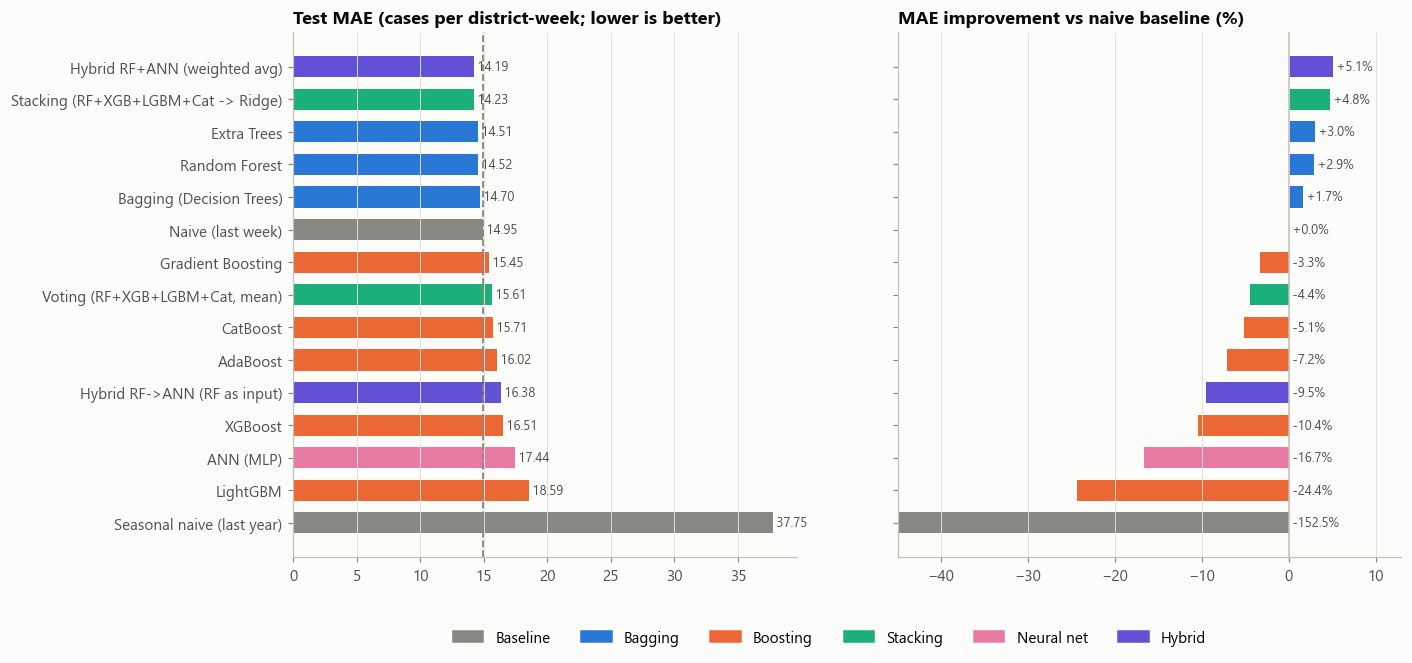

In [4]:
r = res.sort_values("MAE", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), sharey=True)
colors = [viz.FAMILY_COLORS[f] for f in r.family]
axes[0].barh(r.model, r.MAE, color=colors, height=0.65)
axes[0].axvline(naive.MAE, color=viz.MUTED, ls="--", lw=1.2)
axes[0].set_title("Test MAE (cases per district-week; lower is better)")
for i, v in enumerate(r.MAE): axes[0].text(v, i, f" {v:.2f}", va="center", fontsize=8.5, color=viz.INK_2)
axes[1].barh(r.model, r.MAE_vs_naive_pct, color=colors, height=0.65)
axes[1].axvline(0, color=viz.AXIS, lw=1)
axes[1].set_title("MAE improvement vs naive baseline (%)")
for i, v in enumerate(r.MAE_vs_naive_pct): axes[1].text(max(v, 0), i, f" {v:+.1f}%", va="center", fontsize=8.5, color=viz.INK_2)
axes[1].set_xlim(left=max(r.MAE_vs_naive_pct.min(), -40) - 5)
for ax in axes: ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for f, c in viz.FAMILY_COLORS.items() if f in set(r.family)]
fig.legend(handles, [f for f in viz.FAMILY_COLORS if f in set(r.family)], ncol=6, loc="lower center", bbox_to_anchor=(0.5, -0.04))
viz.save(fig, "final_metrics_by_family"); plt.show()

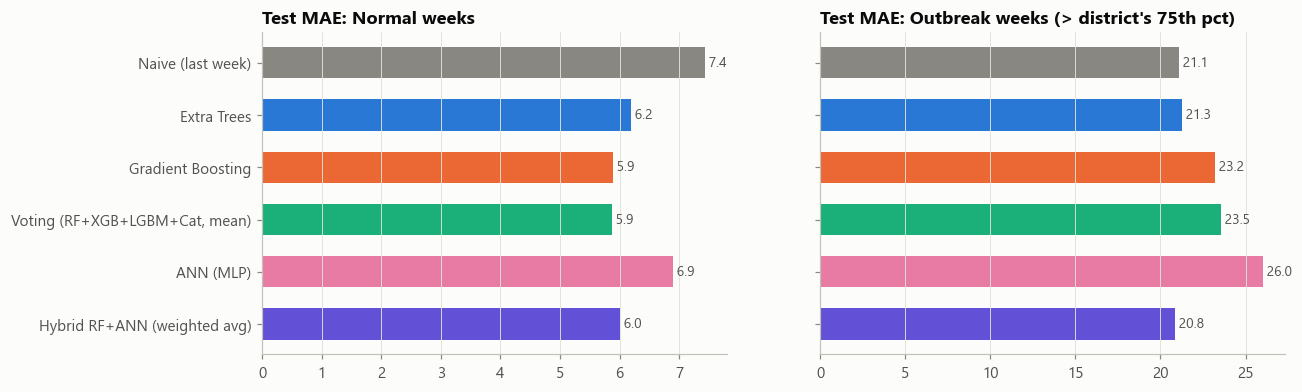

,family,MAE_normal,MAE_outbreak,ratio
model,,,,
Naive (last week),Baseline,7.43,21.06,2.83
Extra Trees,Bagging,6.20,21.26,3.43
Gradient Boosting,Boosting,5.89,23.22,3.94
"Voting (RF+XGB+LGBM+Cat, mean)",Stacking,5.87,23.53,4.01
ANN (MLP),Neural net,6.89,26.02,3.78
Hybrid RF+ANN (weighted avg),Hybrid,6.00,20.85,3.47


In [5]:
show = [E.NAIVE_NAME] + list(family_best.model)
rr = res.set_index("model").loc[show]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col, title in [(axes[0], "MAE_normal", "Normal weeks"), (axes[1], "MAE_outbreak", "Outbreak weeks (> district's 75th pct)")]:
    ax.barh(show[::-1], rr[col].values[::-1], color=[viz.FAMILY_COLORS[f] for f in rr.family][::-1], height=0.6)
    for i, v in enumerate(rr[col].values[::-1]): ax.text(v, i, f" {v:.1f}", va="center", fontsize=9, color=viz.INK_2)
    ax.set_title(f"Test MAE: {title}"); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
viz.save(fig, "final_normal_vs_outbreak"); plt.show()
rr[["family", "MAE_normal", "MAE_outbreak"]].assign(ratio=lambda d: d.MAE_outbreak / d.MAE_normal).round(2)

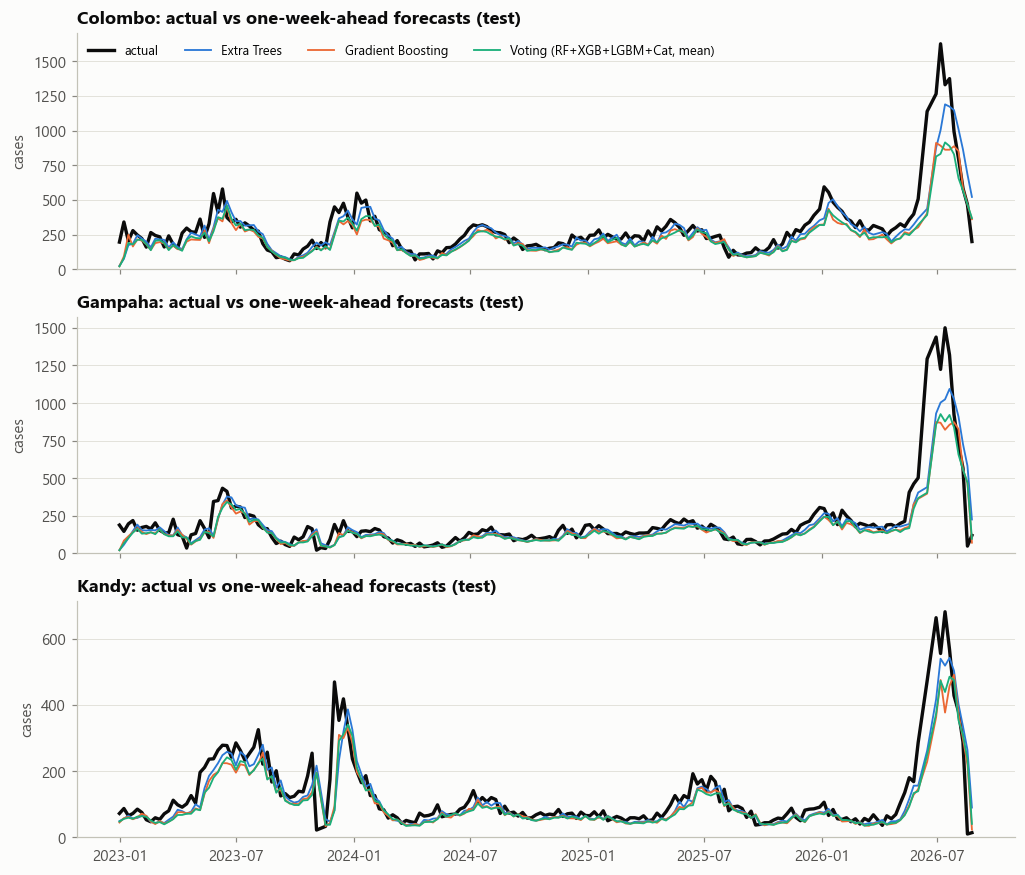

In [6]:
tp = E.load_predictions("test")
lines = [(family_best.loc["Bagging", "model"], viz.SERIES[0]), (family_best.loc["Boosting", "model"], viz.SERIES[1]),
         (family_best.loc["Stacking", "model"], viz.SERIES[2])]
fig, axes = plt.subplots(3, 1, figsize=(11, 9.5), sharex=True)
for ax, dist in zip(axes, ["Colombo", "Gampaha", "Kandy"]):
    p = tp[tp.district == dist].sort_values("target_date")
    ax.plot(p.target_date, p.target, color=viz.INK, lw=2.2, label="actual")
    for m, c in lines:
        ax.plot(p.target_date, p[m], color=c, lw=1.2, label=m)
    ax.set_title(f"{dist}: actual vs one-week-ahead forecasts (test)"); ax.set_ylabel("cases"); ax.set_ylim(0)
axes[0].legend(ncol=4, loc="upper left", fontsize=8.5)
viz.save(fig, "final_actual_vs_predicted"); plt.show()

## 4. Random Forest vs gradient boosting (XGBoost, LightGBM, CatBoost) head-to-head

In [7]:
h2h = ["Random Forest", "Gradient Boosting", "XGBoost", "LightGBM", "CatBoost"]
hh = res.set_index("model").loc[h2h, ["val_MAE", "MAE", "RMSE", "R2", "MAE_normal", "MAE_outbreak", "MAE_vs_naive_pct", "train_time_s"]]
hh.round(3)

,val_MAE,MAE,RMSE,R2,MAE_normal,MAE_outbreak,MAE_vs_naive_pct,train_time_s
model,,,,,,,,
Random Forest,10.393,14.520,37.472,0.868,6.073,21.389,2.874,8.49
Gradient Boosting,10.430,15.447,43.010,0.826,5.894,23.216,-3.327,4.09
XGBoost,10.442,16.508,51.886,0.747,5.926,25.113,-10.425,0.30
LightGBM,10.576,18.593,50.949,0.756,5.983,28.849,-24.376,0.48
CatBoost,10.562,15.714,44.105,0.817,6.139,23.501,-5.115,0.60


## 5. Distribution shift: can tree ensembles forecast bigger outbreaks than they have seen?

In [8]:
# A regression tree predicts the average of training targets in a leaf, so a forest can never predict
# more than the largest value it saw in training (per similar situation). Boosting adds up many trees, so it can in
# principle exceed it, but only slightly. We check how often the test period goes above each district's training maximum.
train_max = tr.groupby("district").target.max()
above = te.target.to_numpy() > te.district.map(train_max).to_numpy()
print(f"test district-weeks above that district's 2007-2021 maximum: {above.sum()} ({above.mean():.1%})")
print("districts affected:", te[above].district.value_counts().to_dict())

ob = E.outbreak_mask(te)
key = [E.NAIVE_NAME] + list(family_best.model)
tp_al = tp.set_index(["district", "target_date"]).loc[list(zip(te.district, te.target_date))]
bias = pd.DataFrame({m: {"mean error, normal weeks": (tp_al[m].to_numpy() - te.target.to_numpy())[~ob].mean(),
                         "mean error, outbreak weeks": (tp_al[m].to_numpy() - te.target.to_numpy())[ob].mean(),
                         "max prediction": tp_al[m].max(), "max actual": te.target.max()} for m in key}).T
print("mean error = prediction - actual (negative = under-prediction)")
bias.round(2)

test district-weeks above that district's 2007-2021 maximum: 17 (0.4%)
districts affected: {'Hambantota': 4, 'Galle': 3, 'Matara': 3, 'Kilinochchi': 2, 'Mullaitivu': 2, 'Monaragala': 1, 'Kalutara': 1, 'Nuwara Eliya': 1}


mean error = prediction - actual (negative = under-prediction)


,"mean error, normal weeks","mean error, outbreak weeks",max prediction,max actual
Naive (last week),3.91,-3.27,1625.00,1625.0
Extra Trees,2.19,-12.44,1188.77,1625.0
Gradient Boosting,1.24,-18.28,910.74,1625.0
"Voting (RF+XGB+LGBM+Cat, mean)",1.16,-18.64,926.48,1625.0
ANN (MLP),3.53,-1.00,3706.15,1625.0
Hybrid RF+ANN (weighted avg),2.14,-9.65,1884.61,1625.0


In [9]:
# Colombo in the 2026 outbreak: how close do the models get to the peak?
p = tp[(tp.district == "Colombo") & (tp.target_date >= "2026-04-01")].sort_values("target_date")
print("Colombo 2007-2021 training maximum:", int(train_max["Colombo"]))
peak = p.loc[p.target.idxmax()]
print(f"2026 peak week {peak.target_date.date()}: actual {peak.target:.0f}")
for m in key:
    print(f"   {m:40s} forecast {peak[m]:7.1f}  ({100*(peak[m]-peak.target)/peak.target:+.0f}%)")

Colombo 2007-2021 training maximum: 1972
2026 peak week 2026-07-06: actual 1625
   Naive (last week)                        forecast  1264.0  (-22%)
   Extra Trees                              forecast  1002.8  (-38%)
   Gradient Boosting                        forecast   890.8  (-45%)
   Voting (RF+XGB+LGBM+Cat, mean)           forecast   832.1  (-49%)
   ANN (MLP)                                forecast  2227.4  (+37%)
   Hybrid RF+ANN (weighted avg)             forecast  1420.0  (-13%)


### Diagnostic: does the log1p target cause the under-prediction in outbreak weeks?
A model trained on log1p(cases) predicts roughly the *mean of the logs*; `expm1` of that is closer to a geometric
mean/median than to the arithmetic mean, so forecasts are biased low, most of all when the spread is large (outbreaks).
This is Jensen's inequality, often called *retransformation bias*. We refit Random Forest and LightGBM with the same tuned
settings on the **raw** target and compare. *Diagnostic only:* the log1p choice was made on validation in notebook 02
and is not changed here.

In [10]:
rows = []
for name in ["Random Forest", "LightGBM"]:
    params, rounds = M.load_best_params(name)
    for use_log in [True, False]:
        if use_log:
            pipe = M.build_final(name, params, cfg, n_rounds=rounds)
        else:   # without the log wrapper the regressor sits at "model__" instead of "model__regressor__"
            pipe = M.make_pipeline(M.CATALOGUE[name][1](), dict(cfg, use_log_target=False))
            pipe.set_params(**{k.replace(M.P, "model__"): v for k, v in params.items()})
            if rounds: pipe.set_params(model__n_estimators=rounds)
        pipe.fit(tr[feats], tr.target)
        p = np.clip(pipe.predict(te[feats]), 0, None)
        err = p - te.target.to_numpy()
        rows.append({"model": name, "target": "log1p" if use_log else "raw",
                     "val_MAE": E.regression_metrics(va.target, pipe.predict(va[feats]))["MAE"],
                     "test_MAE": np.abs(err).mean(), "MAE_normal": np.abs(err)[~ob].mean(),
                     "MAE_outbreak": np.abs(err)[ob].mean(), "mean_error_outbreak": err[ob].mean(),
                     "mean_error_normal": err[~ob].mean()})
log_vs_raw = pd.DataFrame(rows)
log_vs_raw.round(3)

,model,target,val_MAE,test_MAE,MAE_normal,MAE_outbreak,mean_error_outbreak,mean_error_normal
0,Random Forest,log1p,10.393,14.520,6.073,21.389,-11.813,1.796
1,Random Forest,raw,10.670,14.543,7.546,20.232,-2.927,5.305
2,LightGBM,log1p,10.576,18.593,5.983,28.849,-26.234,-0.187
3,LightGBM,raw,10.769,14.602,7.334,20.513,-6.917,4.936


## 6. What drives the forecasts? Feature importance and SHAP

SHAP model (best single tree ensemble by validation): Extra Trees | values are on the log1p scale


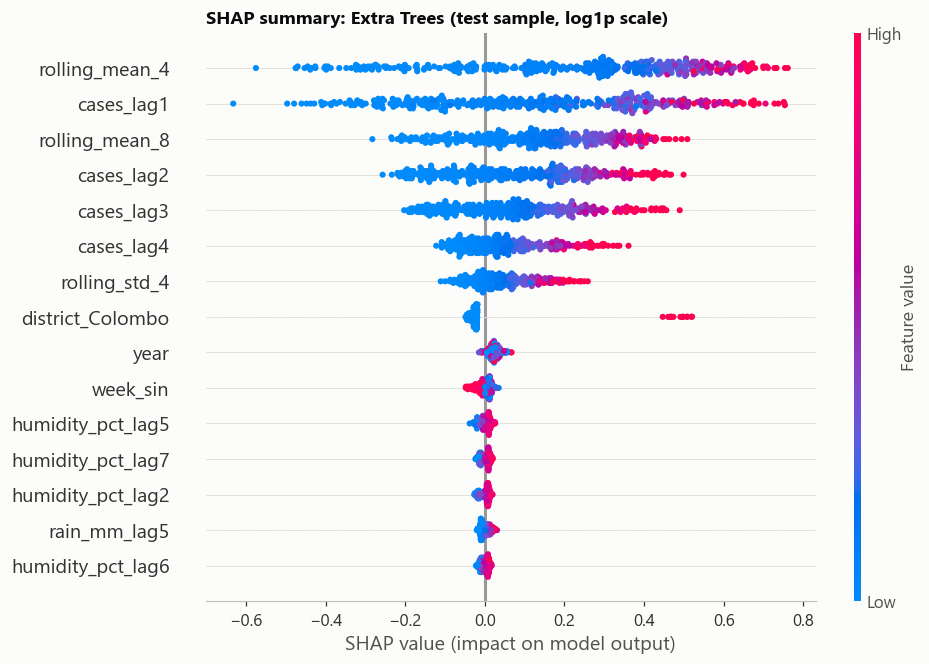

share of mean |SHAP| by feature group: {'recent cases (lags & rolling)': 0.849, 'weather (lags 1-8)': 0.08, 'district': 0.041, 'calendar': 0.03, 'was-missing flags': 0.0}
weather mean |SHAP| by lag (weeks): {1: 0.016, 2: 0.0171, 3: 0.0093, 4: 0.0094, 5: 0.0208, 6: 0.0143, 7: 0.0184, 8: 0.0115}


rolling_mean_4      0.3384
cases_lag1          0.2724
rolling_mean_8      0.1795
cases_lag2          0.1616
cases_lag3          0.1350
cases_lag4          0.0837
rolling_std_4       0.0660
district_Colombo    0.0436
year                0.0242
week_sin            0.0130
dtype: float64

In [11]:
import shap
single = res[res.family.isin(["Bagging", "Boosting"])].sort_values("val_MAE")
shap_model_name = next(m for m in single.model if any(e["name"] == m for e in reg.values()))
pipe = M.load_predictor(shap_model_name)
prep, inner = pipe.named_steps["prep"], pipe.named_steps["model"].regressor_
names = prep.get_feature_names_out()
sample = te.sample(400 if "Forest" in shap_model_name or "Trees" in shap_model_name else 1500, random_state=config.RANDOM_STATE)
Xs = pd.DataFrame(prep.transform(sample[feats]), columns=names)
explainer = shap.TreeExplainer(inner)
sv = explainer.shap_values(Xs)
print("SHAP model (best single tree ensemble by validation):", shap_model_name, "| values are on the log1p scale")
shap.summary_plot(sv, Xs, max_display=15, show=False, plot_size=(9, 6))
plt.title(f"SHAP summary: {shap_model_name} (test sample, log1p scale)", loc="left", fontsize=12, fontweight="bold")
viz.save(plt.gcf(), "shap_summary"); plt.show()

mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=names)
def group(n):
    if n.startswith(("cases", "rolling")): return "recent cases (lags & rolling)"
    if n.startswith(("rain", "temp", "humid")): return "weather (lags 1-8)"
    if n.startswith("district"): return "district"
    if n in ("week_sin", "week_cos", "year"): return "calendar"
    return "was-missing flags"
shap_groups = (mean_abs.groupby(group).sum() / mean_abs.sum()).sort_values(ascending=False)
print("share of mean |SHAP| by feature group:", shap_groups.round(3).to_dict())
weather_lag = mean_abs[[n for n in names if n.startswith(("rain", "humid", "temp"))]]
by_lag = weather_lag.groupby(lambda n: int(n.split("lag")[1])).sum()
print("weather mean |SHAP| by lag (weeks):", by_lag.round(4).to_dict())
mean_abs.sort_values(ascending=False).head(10).round(4)

## 7. Why did the models behave this way?

### 7.1 The naive baseline is strong because dengue is persistent
Weekly cases have a median lag-1 autocorrelation of **0.893** (notebook 01): this week is the best single guide to next
week. "Same as last week" therefore scores MAE **14.95** on test, and SHAP shows every tree model also spends ~**85%** of
its attention on the last 4 weeks of cases and their averages. The realistic goal is not to replace persistence but to
*improve on it*: forecasting the direction of change and smoothing out reporting noise. Every percentage point over
naive is hard-won.

### 7.2 Bagging reduces variance, so it is the most reliable single family
A single deep tree reacts to noise; averaging many de-correlated trees cancels that noise (validation MAE fell 14–27% from
1 tree to the full ensemble, notebook 03). In normal weeks this gives forecasts **17–19% more accurate than naive**
(MAE 6.0–6.2 vs 7.43). In outbreak weeks bagging is about level with naive (21.3–21.8 vs 21.06): an average of past
similar situations moves more slowly than a fast-rising epidemic. Net result: Extra Trees **+3.0%**, Random Forest **+2.9%**,
bagged trees +1.7%. Random Forest also has the lowest time-series CV error over 2007–2021 (13.56), which includes the 2017
and 2019 epidemics.

### 7.3 Boosting reduces bias, but here that bias reduction did not survive the outbreaks
Boosting fits calm, typical weeks best of all (normal-week MAE **5.89–6.33**), which is what sequential bias reduction
should do. But every booster was worse than naive overall (**−3% to −24%**), because outbreak-week errors were 23–29.
Three reasons, each checked:
1. **Log target → retransformation bias.** Models trained on log1p(cases) predict something close to a geometric
   mean; `expm1` turns that into a forecast that is systematically **too low when values are large and volatile**
   (Jensen's inequality). The diagnostic in section 5 shows it: LightGBM on the raw target has test MAE **14.60** (vs
   18.59 with log1p) and an outbreak-week bias of −6.9 instead of −26.2. Random Forest is hardly affected (14.54 vs 14.52)
   because its leaves average whole groups of similar rows, while boosting's additive, shrunken steps in log space
   amplify the effect.
2. **Calm validation year.** Early stopping picked few rounds (10–104) on 2022, a low-incidence year. Using full rounds
   helped XGBoost and LightGBM but hurt AdaBoost, Gradient Boosting and CatBoost (notebook 04), so this is only part of the story.
3. **Shallow trees + shrinkage** need many rounds to reach extreme values; under strong regularisation they stay close
   to typical levels, which is excellent for normal weeks and poor for surges.

The log1p decision was made correctly on validation (it lowered 2022 MAE for both RF and LightGBM), which is exactly why
it is instructive: the validation year did not contain the kind of week where its cost appears.

### 7.4 Stacking helps only if base learners make different errors, and here they mostly did not
The four base models' validation errors are **97.8% correlated**: they rely on the same lag features and miss the same
surges. Simple **voting** therefore gained nothing (−4.4%), because it averaged three under-forecasting boosters with RF.
**Stacking** did better (+4.8%, the best single "pure ensemble"), for a specific reason: the Ridge meta-learner's weights
(RF 0.37, XGBoost 0.40, CatBoost 0.25, LightGBM 0.02) sum to **1.05**, so it scales the forecast up slightly, correcting part
of the shared under-prediction. It learned a *bias correction* more than a *diversity bonus*.

### 7.5 Hybrids work when the components fail in different ways
* **RF + ANN (weighted 0.8 / 0.2) was the best model on test (+5.1%).** Their errors are correlated (0.93), but their
  **biases in outbreaks are opposite**: trees cannot easily push forecasts upward (Extra Trees mean outbreak error −12.4),
  while the neural network, which extrapolates linearly, *over-shoots* (its largest forecast was 3,706 vs a maximum actual of
  1,625; outbreak bias −1.0). A small dose of the ANN lifts the forest's outbreak forecasts; for Colombo's 2026 peak it
  forecast 1,420 vs 1,003 (Extra Trees) and an actual of 1,625.
* **RF → ANN** (forest forecast as an input) did worse (−9.5%): the ANN learned to trust the forest feature and then
  amplified its errors.
* **RF + SARIMA** beat naive on the national total (+4.0%) while SARIMA alone (−2.0%) and RF alone (−17.9%) did not: the
  linear seasonal model supplies a smooth level, the forest corrects its residuals with weather and recent dynamics. For
  Colombo no model beat naive; its June 2026 surge outran every one-week-ahead forecast.

### 7.6 Distribution shift: outbreak-heavy test years, not unseen magnitudes
The test period is very different from training (mean 52.9 vs 30.1 cases per region-week; **55% of test weeks are
"outbreak" weeks**). However, only **0.4%** of test weeks exceed their region's 2007–2021 maximum (Colombo's 2026 peak of
1,625 is below its 2017 record of 1,972). So "trees cannot extrapolate" is true but is **not** the main cause here. The
problem is that outbreak-level weeks were *rare* in training, so trees' leaves average them with calmer weeks, and the log
target pulls forecasts down further. For the best model of each family, error is 3.4–4.0× larger in outbreak weeks than in
normal weeks (naive: 2.8×).

### 7.7 Weather matters a little, with the lag biology predicts
Weather accounts for ~**8%** of the SHAP attribution. The largest weather effects are at lags of **5 and 7 weeks** (rain and humidity),
matching notebook 01 (correlation peaking at 7–9 weeks) and the biology: rain creates breeding sites → eggs to adult
*Aedes* in ~1–2 weeks → the mosquito must bite an infected person and incubate the virus (~8–12 days) → human incubation
(~4–7 days) → symptoms, clinic visit and notification (~1 week). Weather is useful mainly to anticipate *turning points*,
but one week ahead, recent case counts already contain most of that information.

### 7.8 Validation vs test
Validation and test rankings agree only moderately (Spearman 0.74). Selecting on a single calm year (2022) chose
Extra Trees (test +3.0%), while multi-year time-series CV (2007–2021, including epidemics) ranks Random Forest first, and
the test favours combinations that correct outbreak under-prediction. For deployment, validation should cover outbreak years
(e.g. rolling-origin evaluation over several seasons).

## 8. Research notes

### 8.1 Random Forest vs gradient boosting (XGBoost, LightGBM, CatBoost)

| | **Random Forest** (bagging) | **XGBoost** | **LightGBM** | **CatBoost** |
|---|---|---|---|---|
| How trees are built | Deep trees, **in parallel**, each on a bootstrap sample with random feature subsets; predictions **averaged** | Shallow trees **in sequence**; each fits the gradient of the loss of the current ensemble; L1/L2-regularised objective, second-order (Newton) steps | Same idea, but trees grow **leaf-wise** on feature **histograms**; GOSS row sampling, EFB feature bundling | Same idea, with **ordered boosting** (residuals computed by models that never saw the row) and **symmetric (oblivious) trees** |
| Main error it attacks | **Variance** (averaging de-correlated trees) | **Bias** (each round corrects the previous) | Bias | Bias, with less over-fitting on small data |
| Tuning effort | Low: works well near defaults; more trees never hurt accuracy | High: learning rate, depth, rounds, regularisation interact; needs early stopping | High; `num_leaves` must be limited or it over-fits | Moderate; strong defaults |
| Speed | Parallel, but deep trees → large models (MBs per hundred trees) | Fast (histogram method) | Usually the fastest | Slower to train, fast to predict |
| Categorical features | Need encoding (one-hot here) | Need encoding (native support is newer/experimental) | Native categorical splits | Native, via ordered target statistics, its signature feature |
| Over-fitting behaviour | Hard to over-fit by adding trees; OOB estimate for free | Over-fits with too many rounds → early stopping essential | Same; leaf-wise trees over-fit small data | More robust by design |
| Typical result on tabular benchmarks | Strong, robust baseline | Often top accuracy after tuning | Similar accuracy, faster | Often best with many categorical features / little tuning |

In this project, the head-to-head table in section 4 shows how the four compare on the same data. Section 7
explains why the ranking came out as it did here.

### 8.2 Strengths and limitations of tree ensembles: tabular vs image/text data

**Tabular data (like ours): tree ensembles are usually the method of choice.**
* Columns are heterogeneous (counts, rainfall, a district ID, a week number) with different scales and meanings.
  Trees split on one feature at a time with thresholds, so they need **no scaling**, are robust to skew and outliers,
  and handle interactions ("lots of rain *and* July *and* Colombo") automatically.
* They cope with missing values (natively in XGBoost/LightGBM/CatBoost, via imputation + flags here), and they
  give feature importances and exact SHAP values, which matter when a ministry must trust a forecast.
* Benchmarks such as Grinsztajn et al. (2022), *"Why do tree-based models still outperform deep learning on tabular
  data?"*, find that gradient-boosted trees and random forests still beat deep networks on typical medium-sized tabular
  datasets, partly because tabular targets are often irregular functions of a few informative features, which trees
  fit well and neural nets (biased towards smooth functions) do not.
* **Limitations:** trees produce step-wise predictions and **cannot extrapolate** beyond the target range seen in
  training (section 5); they do not model time explicitly (we must hand-craft lags); large forests are big files.

**Images and text: deep learning wins.**
* Pixels and words have *spatial or sequential structure*: meaning comes from local patterns (edges, shapes, n-grams,
  word order) that are the **same wherever they appear**. CNNs (weight sharing, translation invariance) and
  Transformers (attention over sequences, pre-trained on huge corpora) are built for this; trees are not.
* A single pixel or token column is almost meaningless on its own, so axis-aligned threshold splits on raw inputs are
  very inefficient, and the input dimension is huge (a 224×224 RGB image has ~150,000 features).
* Trees can still be useful **on top of learned representations**, e.g. gradient boosting on CNN or Transformer
  embeddings, or for structured metadata alongside images or text.

## 9. Limitations
* **Reporting delays and revisions:** the most recent weeks may still increase as late notifications arrive (we
  excluded the last 2 weeks from testing for this reason); the dashboard's latest week can be an under-count.
* **Reporting errors in the source:** 570 district-weeks (2.1%) had to be flagged as missing, including whole missing
  years, copied weeks and two 2026 weeks whose counts were assigned to the wrong regions. Detection rules can miss
  subtler errors. We did not impute targets; lag gaps are median-imputed with was-missing flags.
* **Only one week ahead:** health planning often needs 2-4 weeks of lead time; accuracy will drop at longer horizons.
* **No mobility, serotype, vector-index or population data:** serotype switches (e.g. DENV-3 re-emergence) and human
  movement drive large outbreaks but are not in the features; cases are counts, not incidence per 100,000.
* **Weather at one point per district:** a single grid point (ERA5 reanalysis) cannot capture local rainfall/breeding
  conditions across a whole district.
* **Models trained on 2007-2021 only:** for real deployment they should be retrained on all data up to the latest week.
* **Single test period:** 2023-2026 is dominated by outbreak years; rankings could differ in a calmer period.

## 10. Save `models/summary.json` for the dashboard

In [12]:
import json
from datetime import date

vp = E.load_predictions("val")
BASE = ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]
_c = vp[BASE].sub(vp.target, axis=0).corr().to_numpy()
base_corr = _c[np.triu_indices(len(BASE), 1)]           # pairwise validation-error correlations

bp = json.loads((config.MODELS_DIR / "best_params.json").read_text())
cv_rank = pd.Series({m: v["cv_mae"] for m, v in bp.items() if v.get("cv_mae") is not None}).sort_values()
arima = pd.read_csv(config.MODELS_DIR / "hybrid_arima_results.csv")
nat = arima[arima.series == "National"].set_index("model")
col = arima[arima.series == "Colombo"].set_index("model")
R = res.set_index("model")
deployed = overall.model            # rule fixed before seeing test results: lowest validation MAE
w_rf = reg["rf_ann_weighted"]["weight_rf"]
bag, boost = res[res.family == "Bagging"], res[res.family == "Boosting"]
stack_r, hyb_r, ann_r = R.loc["Stacking (RF+XGB+LGBM+Cat -> Ridge)"], R.loc["Hybrid RF+ANN (weighted avg)"], R.loc["ANN (MLP)"]
lr = log_vs_raw.set_index(["model", "target"])
meta_w = pd.Series(reg["stacking"]["meta_weights"])


def row(m):
    r = R.loc[m]
    return {"model": m, "family": r.family, "val_MAE": round(r.val_MAE, 3), "MAE": round(r.MAE, 3),
            "RMSE": round(r.RMSE, 3), "MAE_vs_naive_pct": round(r.MAE_vs_naive_pct, 2),
            "MAE_normal": round(r.MAE_normal, 3), "MAE_outbreak": round(r.MAE_outbreak, 3)}


key_findings = [
    f"Next week usually looks like this week, so the simple rule 'next week = this week' is a tough benchmark "
    f"(test MAE {naive.MAE:.2f} cases per region-week). Recent case counts carry about "
    f"{shap_groups.get('recent cases (lags & rolling)', 0):.0%} of the model's reasoning; weather about "
    f"{shap_groups.get('weather (lags 1-8)', 0):.0%}, strongest for rain and humidity 5 and 7 weeks earlier.",
    f"Bagging was the most reliable single family: Random Forest and Extra Trees beat the naive rule by about "
    f"{bag.MAE_vs_naive_pct.max():.0f}% (MAE {bag.MAE.min():.2f}), being "
    f"{100 * (1 - bag.MAE_normal.min() / naive.MAE_normal):.0f}% more accurate in normal weeks while staying about "
    f"level with naive in outbreak weeks.",
    f"Boosting was the most accurate in calm weeks (normal-week MAE {boost.MAE_normal.min():.2f}-{boost.MAE_normal.max():.2f}) "
    f"but under-predicted the 2023-2026 surges, ending {-boost.MAE_vs_naive_pct.max():.0f}-{-boost.MAE_vs_naive_pct.min():.0f}% "
    f"worse than naive. A test showed why: trained on the log of cases, LightGBM scored MAE "
    f"{lr.loc[('LightGBM', 'log1p'), 'test_MAE']:.2f}; trained on raw cases it scored "
    f"{lr.loc[('LightGBM', 'raw'), 'test_MAE']:.2f}, because the log transform pulls forecasts of big outbreaks down.",
    f"Stacking improved on every single model on test (MAE {stack_r.MAE:.2f}, {stack_r.MAE_vs_naive_pct:+.1f}% vs naive) "
    f"even though the base models' errors were {base_corr.mean():.0%} correlated: its meta-learner weights add up to "
    f"{meta_w.sum():.2f}, slightly scaling forecasts up, which offsets the trees' tendency to under-forecast outbreaks. "
    f"Simple averaging (voting) did not ({R.loc['Voting (RF+XGB+LGBM+Cat, mean)', 'MAE_vs_naive_pct']:+.1f}%).",
    f"The best test result came from a hybrid: {w_rf:.0%} Random Forest + {1 - w_rf:.0%} neural network "
    f"(MAE {hyb_r.MAE:.2f}, {hyb_r.MAE_vs_naive_pct:+.1f}% vs naive). The two make opposite mistakes in outbreaks "
    f"(the forest forecasts too low, the network can over-shoot), so blending them cancels part of the error. "
    f"SARIMA + Random Forest on the national total also beat naive ({nat.loc['Hybrid RF+SARIMA', 'MAE_vs_naive_pct']:+.1f}%) "
    f"while each part alone did not.",
]

hybrid_notes = [
    f"RF + SARIMA, national weekly total: hybrid MAE {nat.loc['Hybrid RF+SARIMA', 'MAE']:.0f} cases/week vs naive "
    f"{nat.loc['Naive (last week)', 'MAE']:.0f} ({nat.loc['Hybrid RF+SARIMA', 'MAE_vs_naive_pct']:+.1f}%); SARIMA alone "
    f"{nat.loc['SARIMA alone', 'MAE_vs_naive_pct']:+.1f}%, RF alone {nat.loc['RF alone', 'MAE_vs_naive_pct']:+.1f}%. "
    f"SARIMA supplies the seasonal level, the forest corrects what SARIMA misses.",
    f"RF + SARIMA, Colombo: nothing beat naive (hybrid {col.loc['Hybrid RF+SARIMA', 'MAE_vs_naive_pct']:+.1f}%); "
    f"Colombo's sudden 2026 surge was faster than any model could follow one week ahead.",
    f"RF + ANN weighted average: weight {w_rf:.2f} on the forest, tuned on 2022. Test MAE {hyb_r.MAE:.2f} "
    f"({hyb_r.MAE_vs_naive_pct:+.1f}% vs naive), the best of all models on test; the ANN alone scored "
    f"{ann_r.MAE_vs_naive_pct:+.1f}%.",
    "RF -> ANN (forest forecast as an extra network input): "
    f"{R.loc['Hybrid RF->ANN (RF as input)', 'MAE_vs_naive_pct']:+.1f}% vs naive; feeding one model into the other "
    f"amplified errors in outbreaks instead of cancelling them.",
]

family_text = {
    "Baseline": "Simple rules with no learning, e.g. 'next week = this week'. Every model must beat these to be useful.",
    "Bagging": "Many deep decision trees, each trained on a random resample of the data, are averaged. "
               "Averaging cancels individual trees' mistakes (reduces variance), giving stable forecasts.",
    "Boosting": "Small trees are added one after another, each fixing the errors of those before it (reduces bias). "
                "Very accurate in familiar conditions, but here it was too cautious in sudden surges.",
    "Stacking": "Several different models forecast and a final 'manager' model learns how much to trust each. "
                "It helps most when the models make different mistakes.",
    "Neural net": "A small artificial neural network (MLP) that learns smooth patterns from scaled inputs. "
                  "Unlike trees it can forecast values above anything it has seen, which can over-shoot.",
    "Hybrid": "Two different kinds of model combined: a seasonal time-series model (SARIMA) plus a Random Forest that "
              "corrects its errors, or a Random Forest blended with a neural network.",
}

summary = {
    "generated": str(date.today()),
    "selection_rule": "Lowest validation MAE (2022); test results are reported only.",
    "test_period": [str(te.target_date.min().date()), str(te.target_date.max().date())],
    "n_test_rows": int(len(te)),
    "outbreak_week_share": round(float(E.outbreak_mask(te).mean()), 4),
    "naive": row(E.NAIVE_NAME),
    "winner_per_family": {f: row(family_best.loc[f, "model"]) for f in family_best.index},
    "overall_winner_validation": row(overall.model),
    "best_on_test": row(test_best.model),
    "deployed_model": deployed,
    "cv_mae_ranking_2007_2021": cv_rank.round(3).to_dict(),
    "validation_test_rank_correlation": round(float(rank_corr), 3),
    "stacking_error_correlation": round(float(base_corr.mean()), 4),
    "stacking_meta_weights": meta_w.round(4).to_dict(),
    "log_vs_raw_diagnostic": log_vs_raw.round(3).to_dict(orient="records"),
    "rf_sarima": arima.round(3).to_dict(orient="records"),
    "shap_group_share": shap_groups.round(4).to_dict(),
    "family_explanations": family_text,
    "key_findings": key_findings,
    "hybrid_notes": hybrid_notes,
    "why_best": (
        f"No single family dominated, so the answer has two parts. Among single model families, bagging (Random Forest / "
        f"Extra Trees) was the most reliable: averaging hundreds of deep trees keeps forecasts close to recent case levels "
        f"while removing noise, beating the naive rule by about {bag.MAE_vs_naive_pct.max():.0f}%. Overall, the best test "
        f"results came from combining models whose mistakes partly cancel: stacking ({stack_r.MAE_vs_naive_pct:+.1f}%) and "
        f"the Random Forest + neural network hybrid ({hyb_r.MAE_vs_naive_pct:+.1f}%). Boosting was best in calm weeks but "
        f"worst in outbreaks, because trained on log-cases it under-forecasts surges. The deployed model, {deployed}, "
        f"was chosen in advance by the 2022 validation error; 2022 was a calm year, so validation could not fully "
        f"separate the models' outbreak behaviour."),
}
(config.MODELS_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
M.register("overall_best", deployed, next(e["file"] for e in reg.values() if e["name"] == deployed))
print("deployed model (validation rule):", deployed, "| best on test:", test_best.model)
print("time-series CV MAE ranking (2007-2021 folds):", cv_rank.round(3).to_dict())
for i, k in enumerate(key_findings, 1):
    print(f"{i}. {k}")

deployed model (validation rule): Extra Trees | best on test: Hybrid RF+ANN (weighted avg)
time-series CV MAE ranking (2007-2021 folds): {'Random Forest': 13.56, 'Bagging (Decision Trees)': 13.653, 'CatBoost': 14.418, 'Gradient Boosting': 14.477, 'LightGBM': 14.577, 'XGBoost': 14.881, 'Extra Trees': 14.888, 'AdaBoost': 15.281}
1. Next week usually looks like this week, so the simple rule 'next week = this week' is a tough benchmark (test MAE 14.95 cases per region-week). Recent case counts carry about 85% of the model's reasoning; weather about 8%, strongest for rain and humidity 5 and 7 weeks earlier.
2. Bagging was the most reliable single family: Random Forest and Extra Trees beat the naive rule by about 3% (MAE 14.51), being 19% more accurate in normal weeks while staying about level with naive in outbreak weeks.
3. Boosting was the most accurate in calm weeks (normal-week MAE 5.89-6.33) but under-predicted the 2023-2026 surges, ending 3-24% worse than naive. A test showed why: tra

## Key findings

1. **Persistence is king.** The naive "same as last week" forecast (MAE 14.95) is hard to beat; recent cases carry ~85% of
   the models' SHAP attribution.
2. **Bagging is the most reliable single family** (Extra Trees +3.0%, Random Forest +2.9% vs naive): 17–19% better in
   normal weeks, level with naive in outbreak weeks. Averaging reduces variance.
3. **Boosting is best in calm weeks but worst in outbreaks** (−3% to −24%). The main cause is the log1p target's
   retransformation bias, not tree extrapolation: LightGBM on raw cases scores 14.60 instead of 18.59.
4. **Combining helps when it corrects that shared under-prediction.** Stacking (+4.8%) learned weights summing to 1.05;
   the RF + ANN weighted hybrid (+5.1%, best on test) blends a forest that forecasts too low with a network that can
   over-shoot. Voting (−4.4%) and RF → ANN (−9.5%) did not. RF + SARIMA beat naive on the national total (+4.0%).
5. **Model selection:** by the pre-set rule (validation MAE on 2022) the deployed model is **Extra Trees**; the best test
   model is the **RF + ANN hybrid**. A calm validation year cannot reveal outbreak behaviour, so in practice validation should
   span several seasons including epidemics.